# Customer review sentiment analysis

For WeLoveReviews / Harbor House Cafe, determine how many written reviews are positive, neutral or negative, whether this supports the recorded 4.5/5 average, and which disagreements need review.

First inspect data quality and ratings. Then apply a fixed pretrained model, inspect a small draft audit, and turn the notebook-tested inference into a reusable script. Original reviews and human ratings remain unchanged.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidate_paths = [Path('data/raw/reviews.csv'), Path('../data/raw/reviews.csv')]
data_path = next((path for path in candidate_paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Run this notebook from the repository root or src directory.')

reviews = pd.read_csv(data_path)
expected_columns = ['review_id', 'rating', 'review_text']
assert list(reviews.columns) == expected_columns, 'Unexpected CSV columns.'
print(f'Rows: {reviews.shape[0]:,}; columns: {reviews.shape[1]}')
display(pd.DataFrame({'dtype': reviews.dtypes.astype(str),
                      'missing_values': reviews.isna().sum()}))

Rows: 500; columns: 3


,dtype,missing_values
review_id,int64,0
rating,int64,0
review_text,object,0


## Check data quality

Missing values are only one kind of defect. Next, check identifiers, valid star ratings, blank text and duplicates without changing the source data.

In [2]:
numeric_ratings = pd.to_numeric(reviews['rating'], errors='coerce')
valid_ratings = numeric_ratings.between(1, 5) & numeric_ratings.mod(1).eq(0)
is_text = reviews['review_text'].map(lambda value: isinstance(value, str))
text = reviews.loc[is_text, 'review_text']
stripped_text = text.str.strip()

quality_checks = pd.Series({
    'Missing review IDs': reviews['review_id'].isna().sum(),
    'Repeated nonmissing review IDs (extra rows)': reviews['review_id'].dropna().duplicated().sum(),
    'Missing ratings': reviews['rating'].isna().sum(),
    'Invalid nonmissing ratings': (~valid_ratings & reviews['rating'].notna()).sum(),
    'Missing review texts': reviews['review_text'].isna().sum(),
    'Non-string nonmissing review texts': (~is_text & reviews['review_text'].notna()).sum(),
    'Blank or whitespace-only texts': stripped_text.eq('').sum(),
    'Texts with leading/trailing whitespace': text.ne(stripped_text).sum(),
    'Exact duplicate rows (extra rows)': reviews.duplicated().sum(),
    'Repeated exact review texts (extra rows)': text.duplicated().sum(),
    'Repeated stripped review texts (extra rows)': stripped_text.duplicated().sum(),
}, name='count')
display(quality_checks.to_frame())

repeated_text_mask = reviews['review_text'].duplicated(keep=False) & is_text
if repeated_text_mask.any():
    with pd.option_context('display.max_colwidth', None):
        display(reviews.loc[repeated_text_mask].sort_values('review_text').head(6))

,count
Missing review IDs,0
Repeated nonmissing review IDs (extra rows),0
Missing ratings,0
Invalid nonmissing ratings,0
Missing review texts,0
Non-string nonmissing review texts,0
Blank or whitespace-only texts,0
Texts with leading/trailing whitespace,0
Exact duplicate rows (extra rows),0
Repeated exact review texts (extra rows),7


,review_id,rating,review_text
50,51,4,"Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes just to get water, but overall a solid experience. Will definitely be back!"
112,113,4,"Grabbed a quick coffee at Harbor House Café this morning. Every dish was bursting with flavor. We waited 25 minutes just to get water, but overall a solid experience. Will definitely be back!"
176,177,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
194,195,2,Grabbed a quick coffee at Harbor House Café this morning. The food was bland and overpriced. Our server got our order wrong twice. Probably won't recommend it to friends.
291,292,5,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.
483,484,5,Grabbed a quick coffee at Harbor House Café this morning. The music and decor set the perfect mood. Our server remembered our names by the second visit. Already planning my next visit.


## Explore star ratings

Now summarize all five rating categories and the observed average. This describes the recorded stars, not the sentiment of the written reviews.

,count,percent_of_all_reviews
stars,,
1,12,2.4
2,18,3.6
3,38,7.6
4,72,14.4
5,360,72.0


Average valid rating: 4.500 / 5
Missing or invalid ratings excluded from average: 0


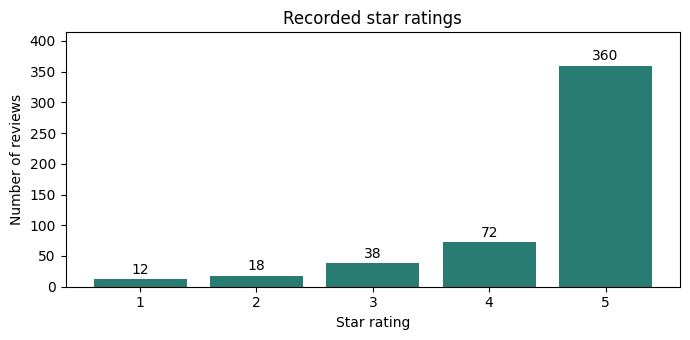

In [3]:
rating_counts = numeric_ratings.loc[valid_ratings].value_counts().reindex(range(1, 6), fill_value=0).sort_index()
rating_summary = pd.DataFrame({
    'count': rating_counts,
    'percent_of_all_reviews': rating_counts.div(len(reviews) or 1).mul(100).round(2),
})
rating_summary.index.name = 'stars'
display(rating_summary)
print(f'Average valid rating: {numeric_ratings.loc[valid_ratings].mean():.3f} / 5')
print(f'Missing or invalid ratings excluded from average: {(~valid_ratings).sum()}')

figure, axis = plt.subplots(figsize=(7, 3.5))
axis.bar(rating_summary.index, rating_summary['count'], color='#287c73')
axis.set(xlabel='Star rating', ylabel='Number of reviews', title='Recorded star ratings', xticks=range(1, 6))
for stars, count in rating_counts.items():
    axis.annotate(str(count), (stars, count), xytext=(0, 4), textcoords='offset points', ha='center')
axis.set_ylim(0, max(rating_counts.max() * 1.15, 1))
figure.tight_layout()
plt.show()

## Measure review length

Measure characters and whitespace-delimited words to understand review size. These word counts are descriptive statistics, not model token counts.

,characters,words
count,500.00,500.00
mean,170.17,29.10
std,27.06,4.82
min,86.00,14.00
25%,155.00,26.00
50%,173.00,29.00
75%,189.00,32.00
max,230.00,42.00


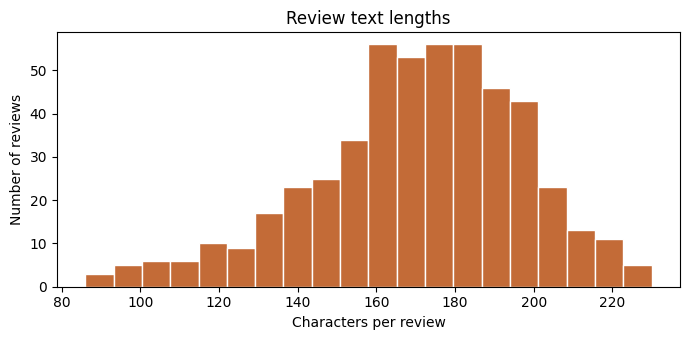

In [4]:
text_lengths = pd.DataFrame({
    'characters': text.str.len(),
    'words': text.str.split().str.len(),
})
display(text_lengths.describe().round(2))

figure, axis = plt.subplots(figsize=(7, 3.5))
axis.hist(text_lengths['characters'], bins=20, color='#c36b37', edgecolor='white')
axis.set(xlabel='Characters per review', ylabel='Number of reviews', title='Review text lengths')
figure.tight_layout()
plt.show()

## Read a small sample

Read one review per available star rating, using a fixed seed for reproducibility. Then inspect review 10 as a deliberately selected mixed-feedback example; this is not a prevalence estimate.

In [5]:
sample_rows = []
for stars in range(1, 6):
    candidates = reviews.loc[valid_ratings & numeric_ratings.eq(stars) & is_text]
    if not candidates.empty:
        sample_rows.append(candidates.sample(n=1, random_state=42))

if sample_rows:
    sample_reviews = pd.concat(sample_rows)
    for review in sample_reviews.itertuples(index=False):
        print(f'Review {review.review_id} | {review.rating} stars')
        print(review.review_text)
        print()

mixed_example = reviews.loc[reviews['review_id'].eq(10)]
if not mixed_example.empty:
    print('Selected mixed-feedback example (not a random sample):')
    for review in mixed_example.itertuples(index=False):
        print(f'Review {review.review_id} | {review.rating} stars')
        print(review.review_text)

Review 442 | 1 stars
Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.

Review 32 | 2 stars
Stopped by Harbor House Café for the first time. My eggs came out cold. The cashier was rude when i asked about the menu. Not sure I'll be returning.

Review 475 | 3 stars
Visited Harbor House Café last weekend. The food was decent, nothing special. Service was fine, nothing memorable. Wouldn't go out of my way, but wouldn't avoid it either.

Review 33 | 4 stars
Regular customer at Harbor House Café here. Every dish was bursting with flavor. The staff were polite but a bit slow, but overall a solid experience. It's fine for a quick stop.

Review 309 | 5 stars
Came to Harbor House Café for a birthday brunch. The music and decor set the perfect mood. The team clearly cares about the customers. Worth every penny. Will definitely be back!

Selected mixed-feedback example (

## Key insights

- **Ratings are concentrated at the top:** the mean is 4.500/5 and 360 of 500 reviews (72%) are five-star. Only 30 reviews (6%) are one- or two-star. Later evaluation should retain coverage of low ratings rather than rely on the overall average.
- **High ratings can include complaints:** review 10 praises pastries but criticizes staff attitude despite its five-star rating. Review 33 also mixes praise with slow service. Later analysis should distinguish overall opinion from food and service feedback; these examples do not quantify corpus-wide alignment.
- **Repeated texts need verification:** seven text entries repeat an earlier exact text despite unique IDs; there are no exact duplicate rows. Confirm whether these are accidental copies or distinct submissions before any later data split, since repeated text could inflate evaluation results.

## Cleaning proposal

No missing-value imputation, rating correction, whitespace cleanup or blank-review removal is needed: all 500 rows have complete required fields, unique IDs, integer ratings within 1-5, and nonblank text without edge whitespace.

The only outstanding check is the repeated text. Verify its origin before removing anything. If these are confirmed accidental copies, retain one record per duplicated text after checking its rating; otherwise keep the records and prevent identical texts from appearing on both sides of a later evaluation split.

Preserve original ratings, punctuation, accents and case. Mixed feedback is not a label error, and repeated wording alone does not prove synthetic data. No cleaning is applied here: keep all 500 submissions for the analysis below.

## Action plan and model choice

Use `nlptown/bert-base-multilingual-uncased-sentiment` to estimate 1-5 stars from text, then map **1-2 negative, 3 neutral, 4-5 positive**. Compare those bands with recorded stars, examine negative/high-rating disagreements, and draft a 20-review audit before drawing conclusions.

The [model card](https://huggingface.co/nlptown/bert-base-multilingual-uncased-sentiment) describes product-review training in six languages, including English. Its star output fits this task, but product reviews differ from cafe service reviews. Published English exact-star agreement of 67% and within-one-star agreement of 95% are not accuracy estimates for this dataset. Mixed feedback, positive expressions involving negation, and repeated phrasing need scrutiny.

Pin both tokenizer and model to commit `8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d`. Load once on CPU, outside the inference loop; Hugging Face caches weights outside the repository. The top-label score is not a calibrated probability of a sentiment band. Start by checking the loaded revision and software versions.

In [6]:
import sys
from importlib.metadata import version

project_root = data_path.resolve().parents[2]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.app import MODEL_ID, MODEL_REVISION, load_classifier, score_reviews

classifier = load_classifier()
assert classifier.model.config._commit_hash == MODEL_REVISION
print(f'Model: {MODEL_ID}\nRevision: {MODEL_REVISION}\nDevice: CPU')
print({package: version(package) for package in ['transformers', 'torch', 'pandas', 'matplotlib']})

Device set to use cpu


Model: nlptown/bert-base-multilingual-uncased-sentiment
Revision: 8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d
Device: CPU
{'transformers': '4.57.1', 'torch': '2.9.0', 'pandas': '2.3.3', 'matplotlib': '3.10.7'}


## Score all reviews

Apply the already-loaded classifier in batches. Keep duplicate submissions and original ratings; add predictions and provenance without changing source text. Token lengths, rather than word counts, determine whether the 512-token limit truncates anything.

In [7]:
scored_reviews = score_reviews(reviews, classifier, batch_size=16)
pd.testing.assert_frame_equal(scored_reviews[reviews.columns], reviews)
assert len(scored_reviews) == 500
assert scored_reviews['predicted_stars'].isin(range(1, 6)).all()
assert scored_reviews['sentiment_score'].between(0, 1).all()
assert scored_reviews['model_revision'].eq(MODEL_REVISION).all()
print(f'Scored reviews: {len(scored_reviews)}')
print(f'Truncated reviews: {scored_reviews.was_truncated.sum()}')
print(f'Rows in repeated-text groups: {scored_reviews.is_repeated_text.sum()}')
display(scored_reviews[['review_id', 'rating', 'predicted_stars', 'sentiment', 'sentiment_score', 'star_gap']].head())

Scored reviews: 500
Truncated reviews: 0
Rows in repeated-text groups: 14


,review_id,rating,predicted_stars,sentiment,sentiment_score,star_gap
0,1,5,5,positive,0.716958,0
1,2,5,5,positive,0.982220,0
2,3,5,5,positive,0.662323,0
3,4,5,5,positive,0.989547,0
4,5,5,5,positive,0.982912,0


## Compare text sentiment with recorded stars

Compare like-for-like sentiment bands first, then examine star differences. Exact and within-one-star agreement measure alignment with recorded ratings, not accuracy against independently verified text sentiment.

,model_count,model_percent,human_rating_count,human_rating_percent
sentiment,,,,
negative,47,9.4,30,6.0
neutral,41,8.2,38,7.6
positive,412,82.4,432,86.4


,value
Human mean stars,4.500
Model mean stars,4.398
Model minus human mean stars,-0.102
Exact star agreement (%),85.800
Within-one-star agreement (%),96.600
Mean absolute star difference,0.230
Sentiment-band agreement (%),95.000


predicted_stars,1,2,3,4,5
rating,,,,,
1,3,9,0,0,0
2,7,9,2,0,0
3,0,3,35,0,0
4,1,0,3,47,21
5,11,4,1,9,335


sentiment,negative,neutral,positive
human_sentiment,,,
negative,28,2,0
neutral,3,35,0
positive,16,4,412


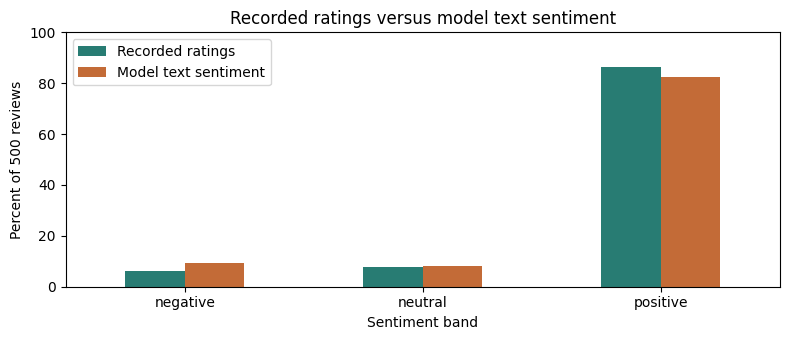

In [8]:
sentiment_bands = ['negative', 'neutral', 'positive']
model_counts = scored_reviews['sentiment'].value_counts().reindex(sentiment_bands, fill_value=0)
human_counts = scored_reviews['human_sentiment'].value_counts().reindex(sentiment_bands, fill_value=0)
sentiment_summary = pd.DataFrame({
    'model_count': model_counts,
    'model_percent': model_counts.div(len(reviews)).mul(100),
    'human_rating_count': human_counts,
    'human_rating_percent': human_counts.div(len(reviews)).mul(100),
})
sentiment_summary.index.name = 'sentiment'
display(sentiment_summary.round(2))

human_mean = pd.to_numeric(scored_reviews['rating']).mean()
model_mean = scored_reviews['predicted_stars'].mean()
absolute_gap = scored_reviews['star_gap'].abs()
agreement_summary = pd.Series({
    'Human mean stars': human_mean,
    'Model mean stars': model_mean,
    'Model minus human mean stars': model_mean - human_mean,
    'Exact star agreement (%)': absolute_gap.eq(0).mean() * 100,
    'Within-one-star agreement (%)': absolute_gap.le(1).mean() * 100,
    'Mean absolute star difference': absolute_gap.mean(),
    'Sentiment-band agreement (%)': scored_reviews.sentiment.eq(scored_reviews.human_sentiment).mean() * 100,
}, name='value')
display(agreement_summary.to_frame().round(3))

star_comparison = pd.crosstab(scored_reviews.rating, scored_reviews.predicted_stars).reindex(
    index=range(1, 6), columns=range(1, 6), fill_value=0,
)
display(star_comparison)
band_comparison = pd.crosstab(scored_reviews.human_sentiment, scored_reviews.sentiment).reindex(
    index=sentiment_bands, columns=sentiment_bands, fill_value=0,
)
display(band_comparison)

figure, axis = plt.subplots(figsize=(8, 3.5))
sentiment_summary[['human_rating_percent', 'model_percent']].rename(
    columns={'human_rating_percent': 'Recorded ratings', 'model_percent': 'Model text sentiment'}
).plot.bar(ax=axis, color=['#287c73', '#c36b37'], rot=0)
axis.set(xlabel='Sentiment band', ylabel='Percent of 500 reviews', title='Recorded ratings versus model text sentiment', ylim=(0, 100))
figure.tight_layout()
plt.show()

## Inspect candidate false negatives

Select model 1-2 stars with recorded 4-5 stars. These are disagreement candidates, not confirmed mistakes: a high rating can coexist with real criticism. Read examples and count recurring phrases to identify patterns worth checking, not to infer what caused the model's decisions.

In [9]:
false_negative_candidates = scored_reviews.loc[
    scored_reviews.predicted_stars.le(2) & pd.to_numeric(scored_reviews.rating).ge(4)
].copy()
print(f'Candidates: {len(false_negative_candidates)} / {len(reviews)} ({len(false_negative_candidates) / len(reviews):.1%})')
if false_negative_candidates.empty:
    print('No negative/high-rating disagreements were found.')
else:
    print('Candidate IDs:', false_negative_candidates.review_id.tolist())
    with pd.option_context('display.max_colwidth', None):
        display(false_negative_candidates[['review_id', 'rating', 'predicted_stars', 'sentiment_score', 'review_text']].head(8))

phrases_to_inspect = ['bursting with flavor', 'accommodate my allergy', 'never disappoints',
                      'but honestly the food made up for it', 'Already planning my next visit']
phrase_counts = pd.DataFrame({
    'candidate_count': [false_negative_candidates.review_text.str.contains(phrase, regex=False, case=False).sum()
                        for phrase in phrases_to_inspect],
    'all_review_count': [scored_reviews.review_text.str.contains(phrase, regex=False, case=False).sum()
                         for phrase in phrases_to_inspect],
}, index=phrases_to_inspect)
phrase_counts.index.name = 'phrase (descriptive association only)'
display(phrase_counts)
print('Candidate top-label score range:', false_negative_candidates.sentiment_score.min(),
      false_negative_candidates.sentiment_score.max())

Candidates: 16 / 500 (3.2%)
Candidate IDs: [14, 15, 73, 87, 138, 200, 204, 254, 270, 322, 332, 409, 440, 462, 474, 489]


,review_id,rating,predicted_stars,sentiment_score,review_text
13,14,4,1,0.444348,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1,0.389344,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1,0.267874,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1,0.324705,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2,0.275116,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2,0.368521,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1,0.349168,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my next visit."
253,254,5,1,0.364092,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!


,candidate_count,all_review_count
phrase (descriptive association only),,
bursting with flavor,12,41
accommodate my allergy,4,38
never disappoints,1,32
but honestly the food made up for it,2,21
Already planning my next visit,11,75


Candidate top-label score range: 0.2678743600845337 0.607707142829895


## Draft 20-review qualitative audit

Select two distinct texts per recorded star rating with seed 42, then add up to ten negative/high-rating candidates ranked by star gap and top-label score; fill any remaining places from large disagreements. This deliberately targeted sample is not representative.

The text-based judgments below were drafted by the assistant after reading the full reviews. They are **drafts for your review**, not blinded independent human labels. Compare overall sentiment rather than assigning precise manual stars, and record evidence and mixed feedback.

In [10]:
unique_reviews = scored_reviews.drop_duplicates('review_text').copy()
unique_reviews['absolute_gap'] = unique_reviews.star_gap.abs()
base_audit = pd.concat([
    group.sample(n=min(2, len(group)), random_state=42)
    for stars, group in unique_reviews.groupby('rating')
]).assign(selection='rating-stratified sample')
unique_candidates = unique_reviews.loc[unique_reviews.predicted_stars.le(2) & unique_reviews.rating.ge(4)]
targeted_audit = unique_candidates.loc[~unique_candidates.review_id.isin(base_audit.review_id)].sort_values(
    ['absolute_gap', 'sentiment_score', 'review_id'], ascending=[False, True, True],
).head(10).assign(selection='targeted disagreement')
review_audit = pd.concat([base_audit, targeted_audit])
if len(review_audit) < 20:
    remaining = unique_reviews.loc[~unique_reviews.review_id.isin(review_audit.review_id)].sort_values(
        ['absolute_gap', 'sentiment_score', 'review_id'], ascending=[False, True, True],
    )
    review_audit = pd.concat([review_audit, remaining.head(20 - len(review_audit)).assign(selection='gap/score fallback')])

text_judgments = {
    442: ('negative', 'coffee tasted burnt', 'Burnt coffee, rude cashier and chaotic space support a negative overall reading.'),
    428: ('negative', 'Disappointing experience overall', 'Food, staff attitude and noise complaints are consistently negative.'),
    32: ('negative', 'My eggs came out cold', 'Cold food, rude service and reluctance to return support a negative reading.'),
    34: ('negative', 'The pastry was stale', 'Stale pastry and repeated order mistakes support a negative reading.'),
    498: ('neutral', 'The coffee was okay', 'Okay coffee and polite but slow staff are lukewarm rather than strongly negative.'),
    170: ('neutral', 'decent, nothing special', 'Decent food and an acceptable quick stop suggest neutral overall opinion despite slow service.'),
    133: ('positive', 'overall a solid experience', 'Strong pastry praise outweighs average service; willingness to return is tentative.'),
    14: ('positive', 'The team clearly cares about the customers', 'Explicit praise and plans to return contradict the negative prediction; no complaint is stated.'),
    308: ('positive', 'Worth every penny', 'Allergy accommodation, atmosphere and recommendation support a positive reading.'),
    64: ('positive', 'This is now my go-to spot', 'Welcoming atmosphere, food praise and repeat-visit commitment are positive.'),
    73: ('positive', 'Service was fast and friendly', 'Food and service praise plus return plans are positive; negative prediction is a suspected error.'),
    332: ('positive', 'The coffee was rich and perfectly brewed', 'Allergy accommodation, coffee praise and return plans are positive; suspected model error.'),
    87: ('positive', 'The seasonal menu never disappoints', 'Positive negation and allergy accommodation express praise; handling negation is a hypothesis, not proven attribution.'),
    489: ('positive', 'Worth every penny', 'Food and staff praise, value and return plans contradict the negative prediction.'),
    204: ('positive', 'but honestly the food made up for it', 'Mixed feedback: rude cashier is real criticism, but explicit food praise and return plans make the overall reading positive.'),
    254: ('positive', 'Will definitely be back!', 'Allergy accommodation and an enthusiastic return intention support a positive reading.'),
    15: ('positive', 'cozy, welcoming vibe', 'Food praise, welcoming atmosphere and plans to return contain no explicit criticism.'),
    270: ('positive', 'Our server remembered our names', 'Personal service, food praise, value and return intention contradict the negative prediction.'),
    409: ('positive', 'Service was fast and friendly', 'Food and service praise plus return plans are positive; suspected model error.'),
    474: ('positive', 'This is now my go-to spot', 'Food and service praise plus repeat-visit commitment are positive; suspected model error.'),
}
assert len(review_audit) == 20 and review_audit.review_text.nunique() == 20
assert set(review_audit.review_id) == set(text_judgments), 'Re-read and update drafts if the audit sample changes.'
review_audit['draft_sentiment'] = review_audit.review_id.map(lambda review_id: text_judgments[review_id][0])
review_audit['evidence_phrase'] = review_audit.review_id.map(lambda review_id: text_judgments[review_id][1])
review_audit['draft_note'] = review_audit.review_id.map(lambda review_id: text_judgments[review_id][2])
review_audit['audit_status'] = 'draft_for_user_review'
review_audit['draft_model_disagreement'] = review_audit.draft_sentiment.ne(review_audit.sentiment)
review_audit['draft_negative_error_candidate'] = review_audit.sentiment.eq('negative') & review_audit.draft_sentiment.isin(['positive', 'neutral'])
assert all(row.evidence_phrase in row.review_text for row in review_audit.itertuples())
display(review_audit[['review_id', 'selection', 'rating', 'predicted_stars', 'sentiment', 'draft_sentiment', 'draft_model_disagreement']])
print('Audit status: assistant drafts; independent user validation pending.\n')
for review in review_audit.itertuples(index=False):
    print(f'Review {review.review_id} | model: {review.sentiment} | draft: {review.draft_sentiment}')
    print(review.review_text)
    print(f'Evidence: {review.evidence_phrase}')
    print(f'Draft note: {review.draft_note}\n')
print(f'Draft/model band disagreements: {review_audit.draft_model_disagreement.sum()} / {len(review_audit)}')
print('Do not interpret this targeted sample proportion as population error or verified model accuracy.')

,review_id,selection,rating,predicted_stars,sentiment,draft_sentiment,draft_model_disagreement
441,442,rating-stratified sample,1,2,negative,negative,False
427,428,rating-stratified sample,1,2,negative,negative,False
31,32,rating-stratified sample,2,1,negative,negative,False
33,34,rating-stratified sample,2,1,negative,negative,False
497,498,rating-stratified sample,3,3,neutral,neutral,False
169,170,rating-stratified sample,3,3,neutral,neutral,False
132,133,rating-stratified sample,4,4,positive,positive,False
13,14,rating-stratified sample,4,1,negative,positive,True
307,308,rating-stratified sample,5,5,positive,positive,False
63,64,rating-stratified sample,5,5,positive,positive,False


Audit status: assistant drafts; independent user validation pending.

Review 442 | model: negative | draft: negative
Visited Harbor House Café last weekend. The coffee tasted burnt. The cashier was rude when i asked about the menu. The place felt cramped and chaotic. Not sure I'll be returning.
Evidence: coffee tasted burnt
Draft note: Burnt coffee, rude cashier and chaotic space support a negative overall reading.

Review 428 | model: negative | draft: negative
Regular customer at Harbor House Café here. The coffee tasted burnt. The staff seemed annoyed to be there. It was way too loud to hold a conversation. Disappointing experience overall.
Evidence: Disappointing experience overall
Draft note: Food, staff attitude and noise complaints are consistently negative.

Review 32 | model: negative | draft: negative
Stopped by Harbor House Café for the first time. My eggs came out cold. The cashier was rude when i asked about the menu. Not sure I'll be returning.
Evidence: My eggs came out 

## What this means for the account manager

The model reads **412 reviews as positive (82.4%), 41 as neutral (8.2%) and 47 as negative (9.4%)**. This supports a broadly positive customer experience, consistent in direction with the recorded **4.500/5** average. It does not mean every five-star review is wholly positive or validate the exact star average from text alone.

The model averages **4.398 stars**, **0.102 below** recorded ratings. Positive recorded ratings cover 86.4% of reviews, versus 82.4% positive model predictions: a four-percentage-point difference. Sentiment bands agree on 95% of rows; exact stars agree on 85.8%. These describe rating alignment, not independently verified text accuracy.

There are **16 negative/high-rating candidates (3.2% of all reviews)**. Some contain clear praise, such as reviews 14 and 73, suggesting model errors pending human confirmation. Review 204 contains genuine criticism of the cashier but says the food made up for it. Twelve candidates share 'bursting with flavor'; repeated positive wording and positive negation deserve inspection, but these associations do not prove why the model failed.

The 20-review draft audit identifies 11 model/draft band disagreements. Because it deliberately targets difficult cases and uses assistant judgments, it cannot establish a general error rate. Product-review training versus cafe-service language, mixed aspects, repeated texts and uncalibrated scores all limit interpretation. No review was truncated, so truncation does not explain these observed disagreements.

**Recommended next action:** have the account manager validate the draft audit and the remaining disagreement cases before acting on individual negative flags. Keep food and service feedback distinct, verify repeated-submission provenance, and use these predictions as screening assistance rather than automatic relabeling or escalation.

## Production handoff

The notebook imports the same pinned loader and batch scorer used by `src/app.py`. The script has no database dependency, loads the model once inside `main()`, and resolves default data paths from its own location.

With Python 3.12, install the exact versions in `requirements.txt`, then run `python src/app.py` from the project root. It writes `data/processed/reviews_with_sentiment.csv`; rerunning replaces that derived file, not the raw CSV. Optional arguments are `--input`, `--output` and `--batch-size`. Run offline tests with `python -m unittest discover -s tests`.

Hugging Face downloads the pinned weights to its normal external cache through `from_pretrained()`. Never copy weights into the repository. Next, check that the generated CSV matches the notebook predictions.

In [11]:
output_path = project_root / 'data/processed/reviews_with_sentiment.csv'
if output_path.is_file():
    exported_reviews = pd.read_csv(output_path)
    pd.testing.assert_frame_equal(exported_reviews, scored_reviews.reset_index(drop=True), check_exact=False, rtol=1e-7, atol=1e-9)
    assert len(exported_reviews) == 500
    assert exported_reviews.model_revision.eq(MODEL_REVISION).all()
    print(f'Production CSV verified: {len(exported_reviews)} rows, preserved input, matching predictions and revision.')
else:
    print('Run python src/app.py from the project root to create the production CSV, then rerun this check.')

Production CSV verified: 500 rows, preserved input, matching predictions and revision.


## Phase checklist

### Phase 1: Notebook arc

- [x] Business objective, EDA, short insights and evidence-based cleaning proposal.
- [x] Action plan and fixed pretrained-model rationale, including limitations.
- [x] Model loaded once before batch inference on all 500 reviews.
- [x] Predicted stars, sentiment mapping, scores and immutable revision recorded.
- [x] Sentiment counts/percentages, star comparisons and gap discussion.
- [x] Negative/high-rating candidates, examples and descriptive patterns documented.
- [x] Twenty distinct texts inspected with evidence-backed assistant draft judgments.
- [x] Plain-language account-manager conclusions and saved executed outputs.
- [ ] Independent human validation of draft judgments and suspected false negatives.

### Phase 2: Production deliverables

- [x] Import-safe reusable inference in `src/app.py`; notebook uses the same helpers.
- [x] All 500 rows written to `data/processed/reviews_with_sentiment.csv` with provenance.
- [x] Direct dependencies pinned to tested versions; external cache and weight safeguards documented.
- [x] Twelve offline tests cover mappings, validation, order, truncation and one-time loading.
- [x] Production CSV checked against the notebook predictions.

The requested analysis and production artifacts are implemented. Draft audit completion does not imply human approval or independently verified model accuracy.